### IPD441 - Visión por Computador
# Clase 11: Autoregressive Models
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Modelos autorregresivos

Los modelos autoregresivos tratan el modelado generativo como un proceso secuencial, condicionando las predicciones a valores anteriores de la secuencia, en lugar de a una variable aleatoria latente. Por lo tanto, intentan modelar explícitamente la distribución generadora de datos en lugar de una aproximación de la misma. En resumen, se basan en la idea de que los valores pasados tienen influencia en los valores futuros. Por ende, predicen la siguiente observación en función de las observaciones previas.

<div align="center">
    <img src="img/autoregressive.png" alt="" width="50%" align="center" />
</div>

# PixelCNN

En 2016, van den Oord et al. introdujeron un modelo que genera imágenes píxel a píxel al predecir la probabilidad del siguiente píxel en función de los anteriores. El modelo se llama [PixelCNN](https://arxiv.org/pdf/1601.06759.pdf) y se puede entrenar para generar imágenes de forma autorregresiva.

<div align="center">
    <img src="img/pixelcnn_faces.jpg" alt="" width="50%" align="center" />
</div>

## Masked Convolutional Layers

Para que podamos aplicar capas convolucionales a la generación de imágenes en un sentido autorregresivo, primero debemos ordenar los píxeles y asegurarnos de que los filtros solo puedan ver los píxeles que preceden al píxel en cuestión. Luego podemos generar imágenes un píxel a la vez, aplicando filtros convolucionales a la imagen actual para predecir el valor del siguiente píxel a partir de todos los píxeles anteriores.

<div align="center">
    <img src="img/Masked_Convolutional_Layers.png" alt="" width="50%" align="center" />
</div>

## Residual Blocks

El bloque residual es una pieza clave del PixelCNN. Un bloque residual es un conjunto de capas donde la salida se agrega a la entrada antes de pasar al resto de la red. En otras palabras, la entrada tiene una ruta rápida hacia la salida, sin tener que pasar por las capas intermedias; esto se denomina conexión de salto. 

<div align="center">
    <img src="img/residual_block.png" alt="" width="20%" align="center" />
</div>

# PixelCNN for LCD digits

In [1]:
from digits import *

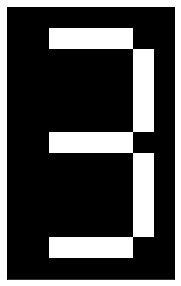

In [2]:
show_as_image(random_digits(fixed_label = 3)[0], figsize=(5,5))

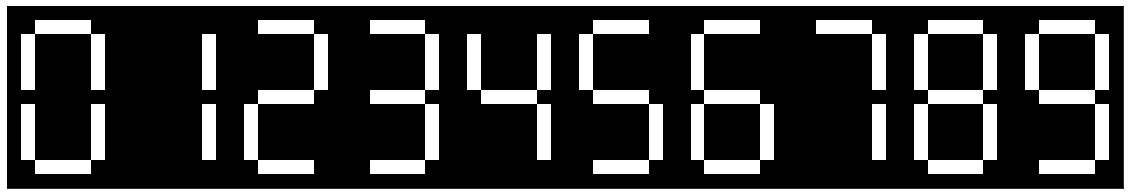

In [3]:
show_as_image(batch_images_to_one(np.stack([random_digits(fixed_label = d)[0] for d in range(10)]), nrows=1))

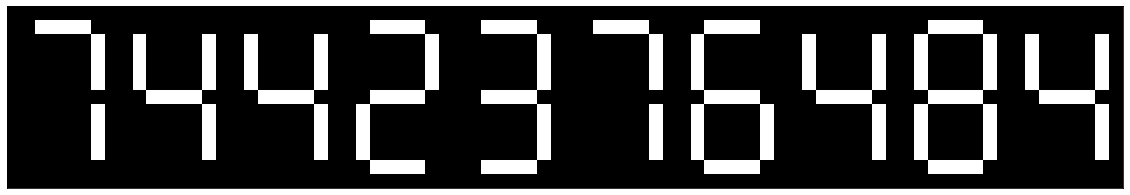

In [4]:
show_as_image(batch_images_to_one(np.stack([random_digits()[0] for _ in range(10)]), nrows=1))

In [5]:
cnn = PixelCNN()
optimizer = torch.optim.Adam(cnn.parameters(), lr = 0.005)

train_dataset = LcdDigits(128 * 50)
train_loader = DataLoader(train_dataset, batch_size = 128)

for epoch in range(25):
    for i, (images, _) in enumerate(train_loader):
        images = Variable(images)
        optimizer.zero_grad()
        loss = F.cross_entropy(input=cnn(images), target=torch.squeeze(images).long())
        loss.backward()
        optimizer.step()

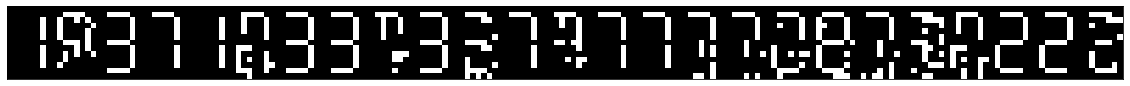

In [6]:
show_as_image(batch_images_to_one(generate_samples(cnn, n_samples=5), nrows=1))

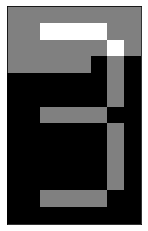

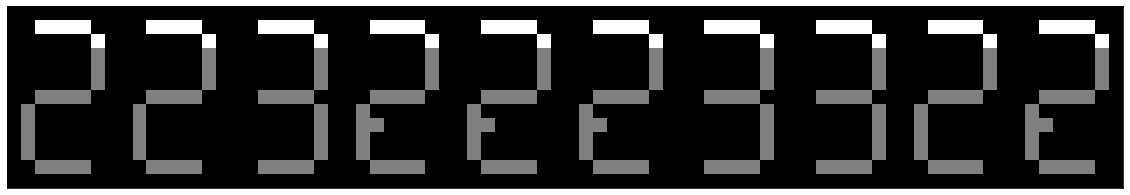

In [7]:
digit_completion(cnn, digit=3, n_digits=10, starting_point = (3,4))

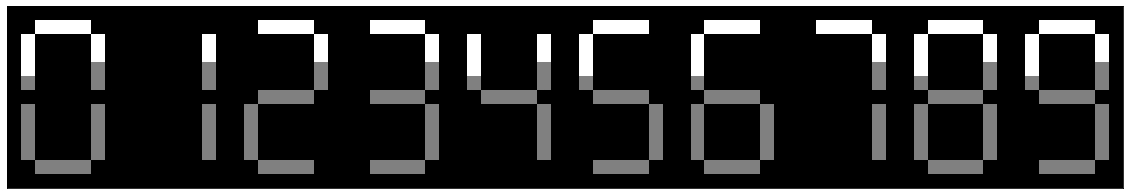

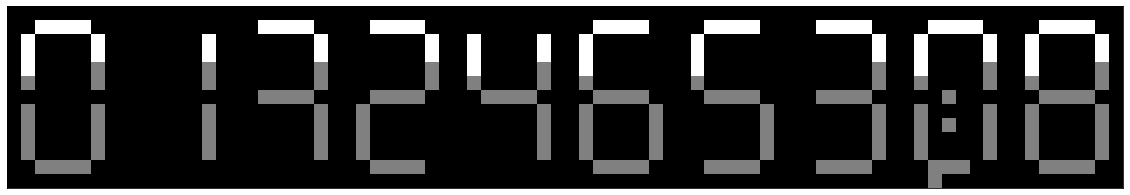

In [8]:
all_digits_completion(cnn, nrows=1, n_digits=10)

# PixelCNN in Fashion-MNIST

In [9]:
from tensorflow.keras import datasets, layers, models, optimizers, callbacks

from utils import display

In [10]:
from pixelcnn import *

In [11]:
IMAGE_SIZE = 16
PIXEL_LEVELS = 4
N_FILTERS = 128
RESIDUAL_BLOCKS = 5

In [12]:
(x_train, _), (_, _) = datasets.fashion_mnist.load_data()

In [13]:
input_data, output_data = preprocess(x_train)

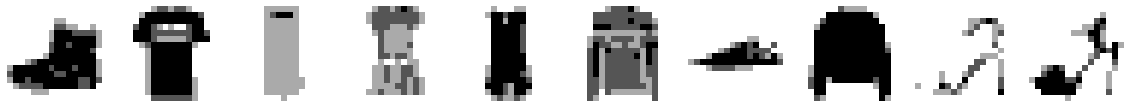

In [14]:
display(input_data)

In [15]:
inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 1))
x = MaskedConv2D(
    mask_type="A",
    filters=N_FILTERS,
    kernel_size=7,
    activation="relu",
    padding="same",
)(inputs)

for _ in range(RESIDUAL_BLOCKS):
    x = ResidualBlock(filters=N_FILTERS)(x)

for _ in range(2):
    x = MaskedConv2D(
        mask_type="B",
        filters=N_FILTERS,
        kernel_size=1,
        strides=1,
        activation="relu",
        padding="valid",
    )(x)

out = layers.Conv2D(
    filters=PIXEL_LEVELS,
    kernel_size=1,
    strides=1,
    activation="softmax",
    padding="valid",
)(x)
pixel_cnn = models.Model(inputs, out)

In [16]:
pixel_cnn.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 1)]       0         
                                                                 
 masked_conv2d (MaskedConv2D  (None, 16, 16, 128)      6400      
 )                                                               
                                                                 
 residual_block (ResidualBlo  (None, 16, 16, 128)      53504     
 ck)                                                             
                                                                 
 residual_block_1 (ResidualB  (None, 16, 16, 128)      53504     
 lock)                                                           
                                                                 
 residual_block_2 (ResidualB  (None, 16, 16, 128)      53504     
 lock)                                                       

In [17]:
adam = optimizers.Adam(learning_rate=0.0005)
pixel_cnn.compile(optimizer=adam, loss="sparse_categorical_crossentropy")

In [18]:
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

In [19]:
img_generator_callback = ImageGenerator(num_img=10)

In [12]:
history = pixel_cnn.fit(
    input_data,
    output_data,
    batch_size=128,
    epochs=50,
    callbacks=[tensorboard_callback, img_generator_callback],
)

Epoch 1/50
469/469 [==============================] - 261s 552ms/step - loss: 0.4878
Epoch 2/50
469/469 [==============================] - 251s 534ms/step - loss: 0.4004
Epoch 3/50
469/469 [==============================] - 249s 532ms/step - loss: 0.3891
Epoch 4/50
469/469 [==============================] - 252s 536ms/step - loss: 0.3821
Epoch 5/50
469/469 [==============================] - 250s 534ms/step - loss: 0.3774
Epoch 6/50
469/469 [==============================] - 251s 534ms/step - loss: 0.3744
Epoch 7/50
469/469 [==============================] - 262s 558ms/step - loss: 0.3715
Epoch 8/50
469/469 [==============================] - 271s 578ms/step - loss: 0.3690
Epoch 9/50
469/469 [==============================] - 271s 578ms/step - loss: 0.3668
Epoch 10/50
469/469 [==============================] - 267s 570ms/step - loss: 0.3648
Epoch 11/50
469/469 [==============================] - 273s 582ms/step - loss: 0.3628
Epoch 12/50
469/469 [==============================] - 263s 560

In [ ]:
pixel_cnn.save("./weights/")

In [20]:
pixel_cnn.load_weights("./weights/");

In [21]:
import os
import ipywidgets as widgets
from IPython.display import display as disp
from PIL import Image  # Import the Image class from PIL

# Folder containing images
folder_path = "output/"

# List all files in the folder
image_files = sorted([file for file in os.listdir(folder_path) 
                      if file.startswith("generated_img_") and file.endswith(".png")])

# Create a function to display the image based on the slider value
def display_image(image_number):
    filename = image_files[image_number - 1]
    img = Image.open(os.path.join(folder_path, filename))
    disp(img)

# Create a slider
image_slider = widgets.IntSlider(min=1, max=len(image_files), description='Epoch:')
initial_image_number = 1

In [22]:
widgets.interact(display_image, image_number=image_slider);

interactive(children=(IntSlider(value=1, description='Epoch:', max=50, min=1), Output()), _dom_classes=('widge…

In [23]:
generated_images = generate_imgs(pixel_cnn, num_img=10, temperature=1.0)

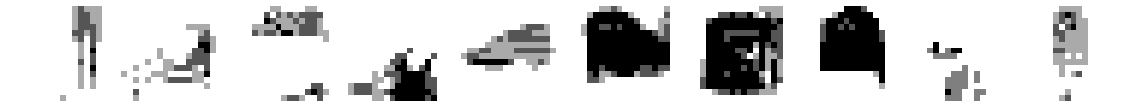

In [24]:
display(generated_images)

# ImageGPT

- ImageGPT es un modelo autoregresivo para generar imágenes, inspirado directamente en GPT-2.

- En lugar de procesar texto, procesa imágenes como secuencias de tokens (como un lenguaje visual).

- Entrenado para predecir el siguiente píxel (token) dado el contexto previo.


# Arquitectura de ImageGPT

<div align="center">
    <img src="img/imagegpt_architecture.png" alt="" width="100%" align="center" />
</div>

In [1]:
import torch
from transformers import ImageGPTModel, ImageGPTImageProcessor
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Función para mostrar múltiples imágenes lado a lado
def show_images(imgs, title=''):
    fig, axs = plt.subplots(1, len(imgs), figsize=(2.5 * len(imgs), 2.5))
    for i, img in enumerate(imgs):
        axs[i].imshow(img)
        axs[i].axis("off")
        axs[i].set_title(f"Paso {i}")
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()

In [3]:
def decode_imagegpt_tokens(tokens):
    """Convierte los tokens a una imagen RGB de 32x32 usando la paleta de ImageGPT."""
    # ImageGPT usa una paleta de 512 colores (8x8x8)
    palette = torch.tensor([[r, g, b] for r in range(0, 256, 32)
                                      for g in range(0, 256, 32)
                                      for b in range(0, 256, 32)], dtype=torch.uint8)

    # tokens: [1024] (32x32)
    pixels = palette[tokens]
    img = pixels.view(32, 32, 3).numpy()
    return img

In [4]:
def show_generated_images(input_image, generated_images, max_cols=8):
    total = len(generated_images) + 1  # +1 por la imagen original
    cols = min(max_cols, total)
    rows = (total + cols - 1) // cols

    fig, axs = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))

    # Asegurarse que axs es 2D
    axs = np.array(axs).reshape(rows, cols)

    all_images = [np.array(input_image)] + generated_images

    for idx, img in enumerate(all_images):
        r, c = divmod(idx, cols)
        axs[r, c].imshow(img, interpolation='nearest')  # 'nearest' ayuda a ver píxeles
        axs[r, c].axis('off')
        axs[r, c].set_title("Input" if idx == 0 else f"Step {idx}")

    # Ocultar subplots vacíos
    for i in range(total, rows * cols):
        r, c = divmod(i, cols)
        axs[r, c].axis('off')

    plt.tight_layout()
    plt.show()

In [5]:
def imagegpt_step_by_step(image_path, steps=8, model_name="openai/imagegpt-small"):
    # 1. Cargar modelo y preprocesador
    model = ImageGPTModel.from_pretrained(model_name)
    processor = ImageGPTImageProcessor.from_pretrained(model_name)
    model.eval()

    # 2. Cargar imagen, redimensionar a 32x32
    image = Image.open(image_path).convert("RGB")
    image = image.resize((32, 32))

    # 3. Preprocesar imagen → produce input_ids directamente
    inputs = processor(images=image, return_tensors="pt")
    input_ids = inputs['input_ids']  # [1, 1024]

    start_len = input_ids.shape[-1]
    max_len = 1024
    step_size = (max_len - start_len) // steps
    current_ids = input_ids.clone()
    generated_images = []

    with torch.no_grad():
        for step in range(steps):
            for _ in range(step_size):
                outputs = model(input_ids=current_ids)
                logits = outputs.logits
                next_token_logits = logits[:, -1, :]
                next_token = torch.argmax(next_token_logits, dim=-1).unsqueeze(0)
                current_ids = torch.cat([current_ids, next_token], dim=-1)

            # Decodificar tokens a imagen RGB
            img_array = decode_imagegpt_tokens(current_ids[0])
            generated_images.append(img_array)

    # Mostrar imagen original + generaciones paso a paso
    show_generated_images(image, generated_images, max_cols=8)

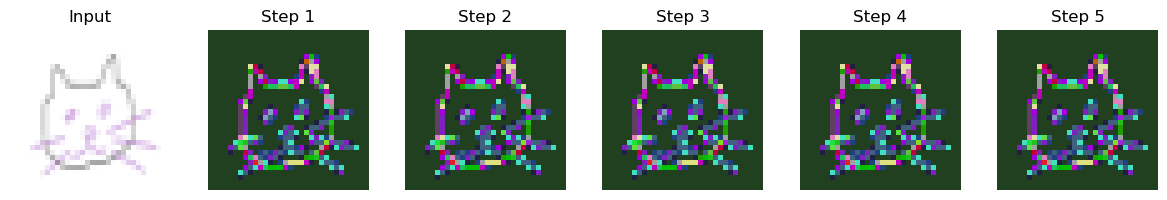

In [10]:
imagegpt_step_by_step(image_path="img/cat-sketch.png", steps=5)

# Sketch-RNN

- Toma como entrada los trazos parciales de un dibujo y aprende a predecir los próximos pasos de forma coherente. Esto lo hace usando una arquitectura encoder-decoder basada en RNNs.
- El codificador toma la secuencia inicial de trazos y genera un vector que resume la información. Ese vector se pasa al decodificador, que comienza a generar nuevos trazos desde ese estado.
- Cada paso del dibujo no es una imagen, sino un vector con coordenadas relativas y señales sobre si el lápiz debe seguir o detenerse.
- Probar en: https://magenta.tensorflow.org/assets/sketch_rnn_demo/index.html y https://magenta.tensorflow.org/assets/sketch_rnn_demo/multi_predict.html

# Overview of Model

<div align="center">
    <img src="img/sketch-rnn.svg" alt="" width="100%" align="center" />
</div>